# Vamos a practicar un poco de pandas y de visualización de datos

## Objetivo

Explorar y visualizar un dataset haciendo uso de pandas, matplotlib y seaborn

## El dataset

El data set que utilizaremos, contiene información de diversos vinos.

El contenido es el siguiente:

    Points: Puntaje en escala 1-100 que le otorgó  WineEnthusiast (aunque dicen sólo reseñar vinos con puntaje >= 80).
      
    Variety: La variedad de uvas usadas para hacer el vino (ie Pinot Noir).
    
    Description: Oraciones de un sommelier describiendo el sabor, olor, aspecto, etc..
    
    Country: País de origen del vino.
    
    Province: Provincia o estado de donde proviene el vino.
    
    Region 1: La región donde crece el vino dentro de una provincia o estado (ie Napa).
    
    Region 2: Algunas veces hay regiones más específicas dentro de una región, esto puede estar vacío.
    
    Winery: La bodega que hizo el vino.
    
    Designation: El viñedo dentro de la viña donde provienen las uvas con las que se hizo el vino.
    
    Price: El costo por botella de vino.
    
   
    

El data set fue obtenido de: https://www.kaggle.com/zynicide/wine-reviews/data

Credito por la elaboración a : zackthoutt

### Librerías

Primero, hay que importar las librerías que vamos a utilizar

In [1]:
import numpy as np                #Álgebra Lineal
import pandas as pd               #Manejo de dataframes
import matplotlib.pyplot as plt   #Visualización
import seaborn as sns             #Visualización


### Cargando el dataset

In [2]:
vino = pd.read_csv("winemag-data_first150k.csv")

Observemos nuestro dataset

In [3]:
vino

,Unnamed: 0,country,description,designation,points,price,province,region_1,region_2,variety,winery
0,0,US,This tremendous 100% varietal wine hails from ...,Martha's Vineyard,96,235.0,California,Napa Valley,Napa,Cabernet Sauvignon,Heitz
1,1,Spain,"Ripe aromas of fig, blackberry and cassis are ...",Carodorum Selección Especial Reserva,96,110.0,Northern Spain,Toro,NaN,Tinta de Toro,Bodega Carmen Rodríguez
2,2,US,Mac Watson honors the memory of a wine once ma...,Special Selected Late Harvest,96,90.0,California,Knights Valley,Sonoma,Sauvignon Blanc,Macauley
3,3,US,"This spent 20 months in 30% new French oak, an...",Reserve,96,65.0,Oregon,Willamette Valley,Willamette Valley,Pinot Noir,Ponzi
4,4,France,"This is the top wine from La Bégude, named aft...",La Brûlade,95,66.0,Provence,Bandol,NaN,Provence red blend,Domaine de la Bégude
5,5,Spain,"Deep, dense and pure from the opening bell, th...",Numanthia,95,73.0,Northern Spain,Toro,NaN,Tinta de Toro,Numanthia
6,6,Spain,Slightly gritty black-fruit aromas include a s...,San Román,95,65.0,Northern Spain,Toro,NaN,Tinta de Toro,Maurodos
7,7,Spain,Lush cedary black-fruit aromas are luxe and of...,Carodorum Único Crianza,95,110.0,Northern Spain,Toro,NaN,Tinta de Toro,Bodega Carmen Rodríguez
8,8,US,This re-named vineyard was formerly bottled as...,Silice,95,65.0,Oregon,Chehalem Mountains,Willamette Valley,Pinot Noir,Bergström
9,9,US,The producer sources from two blocks of the vi...,Gap's Crown Vineyard,95,60.0,California,Sonoma Coast,Sonoma,Pinot Noir,Blue Farm


La primera columna no da información, por lo que la eliminaremos

In [4]:
vino = vino.iloc[:,1:]

Veamos el resultado

In [5]:
vino.head()

,country,description,designation,points,price,province,region_1,region_2,variety,winery
0,US,This tremendous 100% varietal wine hails from ...,Martha's Vineyard,96,235.0,California,Napa Valley,Napa,Cabernet Sauvignon,Heitz
1,Spain,"Ripe aromas of fig, blackberry and cassis are ...",Carodorum Selección Especial Reserva,96,110.0,Northern Spain,Toro,NaN,Tinta de Toro,Bodega Carmen Rodríguez
2,US,Mac Watson honors the memory of a wine once ma...,Special Selected Late Harvest,96,90.0,California,Knights Valley,Sonoma,Sauvignon Blanc,Macauley
3,US,"This spent 20 months in 30% new French oak, an...",Reserve,96,65.0,Oregon,Willamette Valley,Willamette Valley,Pinot Noir,Ponzi
4,France,"This is the top wine from La Bégude, named aft...",La Brûlade,95,66.0,Provence,Bandol,NaN,Provence red blend,Domaine de la Bégude


### Exploración y limpieza en pandas

Queremos conocer nuestro data ser, así que podemos simplemente imprimirlo y observar qué campos encontramos...

In [6]:
vino

,country,description,designation,points,price,province,region_1,region_2,variety,winery
0,US,This tremendous 100% varietal wine hails from ...,Martha's Vineyard,96,235.0,California,Napa Valley,Napa,Cabernet Sauvignon,Heitz
1,Spain,"Ripe aromas of fig, blackberry and cassis are ...",Carodorum Selección Especial Reserva,96,110.0,Northern Spain,Toro,NaN,Tinta de Toro,Bodega Carmen Rodríguez
2,US,Mac Watson honors the memory of a wine once ma...,Special Selected Late Harvest,96,90.0,California,Knights Valley,Sonoma,Sauvignon Blanc,Macauley
3,US,"This spent 20 months in 30% new French oak, an...",Reserve,96,65.0,Oregon,Willamette Valley,Willamette Valley,Pinot Noir,Ponzi
4,France,"This is the top wine from La Bégude, named aft...",La Brûlade,95,66.0,Provence,Bandol,NaN,Provence red blend,Domaine de la Bégude
5,Spain,"Deep, dense and pure from the opening bell, th...",Numanthia,95,73.0,Northern Spain,Toro,NaN,Tinta de Toro,Numanthia
6,Spain,Slightly gritty black-fruit aromas include a s...,San Román,95,65.0,Northern Spain,Toro,NaN,Tinta de Toro,Maurodos
7,Spain,Lush cedary black-fruit aromas are luxe and of...,Carodorum Único Crianza,95,110.0,Northern Spain,Toro,NaN,Tinta de Toro,Bodega Carmen Rodríguez
8,US,This re-named vineyard was formerly bottled as...,Silice,95,65.0,Oregon,Chehalem Mountains,Willamette Valley,Pinot Noir,Bergström
9,US,The producer sources from two blocks of the vi...,Gap's Crown Vineyard,95,60.0,California,Sonoma Coast,Sonoma,Pinot Noir,Blue Farm


... esto sólo implicaría leer 150,930 filas de información. Si contamos las 10 columnas, estariamos enfrentando 1,509,300 entradas de información.

Pero también podemos hacer uso de pandas junto con la descripción de las variables que vimos al inicio para entender nuestro conjunto de datos. Primero veamos el número de observaciones y de variables que tenemos.

In [7]:
print ("Número de observaciones: " + str(vino.shape[0]) )
print ("Número de columnas: " + str(vino.shape[1]) )

Número de observaciones: 150930
Número de columnas: 10


También podemos ver fácilmente el nombre de todas las columnas/variables:

In [8]:
for i in range(0,len(vino.columns)):
    print("Variable " + str(i+1) + ": " + list(vino)[i])


Variable 1: country
Variable 2: description
Variable 3: designation
Variable 4: points
Variable 5: price
Variable 6: province
Variable 7: region_1
Variable 8: region_2
Variable 9: variety
Variable 10: winery


Podemos notar que dos columnas deberían tener valores numéricos. Siempre es importante corroborar que los datos sean importados en el formato adecuado:

In [9]:
vino.dtypes

country         object
description     object
designation     object
points           int64
price          float64
province        object
region_1        object
region_2        object
variety         object
winery          object
dtype: object

Una vez que notamos que las variables están en el formato adecuado podemos continuar conociendo nuestro dataset

Comencemos con la primera variable: países. ¿Podemos saber cuántos países diferentes hay?

In [10]:
list(vino["country"].unique())

['US',
 'Spain',
 'France',
 'Italy',
 'New Zealand',
 'Bulgaria',
 'Argentina',
 'Australia',
 'Portugal',
 'Israel',
 'South Africa',
 'Greece',
 'Chile',
 'Morocco',
 'Romania',
 'Germany',
 'Canada',
 'Moldova',
 'Hungary',
 'Austria',
 'Croatia',
 'Slovenia',
 nan,
 'India',
 'Turkey',
 'Macedonia',
 'Lebanon',
 'Serbia',
 'Uruguay',
 'Switzerland',
 'Albania',
 'Bosnia and Herzegovina',
 'Brazil',
 'Cyprus',
 'Lithuania',
 'Japan',
 'China',
 'South Korea',
 'Ukraine',
 'England',
 'Mexico',
 'Georgia',
 'Montenegro',
 'Luxembourg',
 'Slovakia',
 'Czech Republic',
 'Egypt',
 'Tunisia',
 'US-France']

¿Qué observamos? Una lista de países, pero también missing values. Esto puede presentarse en otros campos. Vamos a comprobarlo

In [11]:
vino.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150930 entries, 0 to 150929
Data columns (total 10 columns):
country        150925 non-null object
description    150930 non-null object
designation    105195 non-null object
points         150930 non-null int64
price          137235 non-null float64
province       150925 non-null object
region_1       125870 non-null object
region_2       60953 non-null object
variety        150930 non-null object
winery         150930 non-null object
dtypes: float64(1), int64(1), object(8)
memory usage: 11.5+ MB


¿Qué hacer entonces? Lidiar con missing values siempre es complicado. Un enfoque que puede utilizarse es quedarse con las observaciones que cuenten con información completa. Otro es elimnar variables que no sean relevantes para el trabajo que se desea hacer. También pueden llenarse los valores haciendo uso de distintos métodos, por ejemplo usando promedios. No existe una regla y la elección depende de cómo sea el dataset y cuál sea el objetivo de utilizarlo. 

En este caso queremos practicar visualización y exploración de datos, por lo que eliminar las observaciones que no estén completas no sería muy grave.

Algo importante es que la variable region_2 tiene muchos missing values, así que podemos eliminar esta columna para no perder tantas observaciones.

In [12]:
vino.drop("region_2", axis = 1, inplace=True)
vino.dropna(inplace=True)

In [13]:
vino.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 77284 entries, 0 to 150928
Data columns (total 9 columns):
country        77284 non-null object
description    77284 non-null object
designation    77284 non-null object
points         77284 non-null int64
price          77284 non-null float64
province       77284 non-null object
region_1       77284 non-null object
variety        77284 non-null object
winery         77284 non-null object
dtypes: float64(1), int64(1), object(7)
memory usage: 5.9+ MB


Ahora que sabemos que no tenemos missing values, podemos proceder con la exploración de datos. Repasemos después de la limpieza con cuántos países nos quedamos:

In [14]:
i = 0
for pais in list(vino["country"].unique()):
    i +=1
    print("País " + str(i) + ": " + pais)
    

País 1: US
País 2: Spain
País 3: France
País 4: Italy
País 5: Argentina
País 6: Canada
País 7: Australia


Nuestra segunda columna es **designation**, veamos en qué viñedos se produce el vino:

In [15]:
vino["designation"].unique()

array(["Martha's Vineyard", 'Carodorum Selección Especial Reserva',
       'Special Selected Late Harvest', ..., 'Grand Cru Muenchberg',
       'Andlau', 'Bungalow Red'], dtype=object)

Parece que la lista es muy grande, pero podemos conocer el número de viñedos facilmente:

In [16]:
print ( "Número de viñedos: " + str(len(vino["designation"].unique())))

Número de viñedos: 23312


Las siguientes variables son **points** y **price**.

In [17]:
vino["points"].unique()

array([ 96,  95,  94,  90,  91,  86,  89,  88,  87,  93,  92,  85,  84,
        83,  82,  81,  99,  98,  97,  80, 100], dtype=int64)

In [18]:
vino["price"].unique()

array([  235.,   110.,    90.,    65.,    66.,    73.,    60.,    80.,
          48.,   185.,   325.,   290.,    75.,    24.,    79.,   220.,
          45.,    62.,   105.,    37.,    22.,    42.,   135.,    29.,
          17.,    26.,    39.,    69.,    30.,   100.,    28.,    25.,
          36.,    38.,    85.,    50.,    54.,    59.,    13.,    14.,
          15.,    10.,    20.,    12.,   125.,    49.,    93.,    32.,
          18.,    44.,    23.,    16.,    40.,    57.,    34.,    58.,
          61.,   200.,    35.,    55.,    56.,    92.,    94.,    27.,
          43.,    33.,    70.,   155.,    95.,    68.,    63.,   115.,
          41.,    46.,    98.,    52.,    31.,    11.,    19.,    64.,
         120.,    91.,    21.,   111.,    88.,    74.,    77.,     9.,
          87.,   113.,   500.,    51.,   150.,    72.,   103.,   136.,
         141.,   102.,    47.,    96.,    78.,   149.,   140.,   138.,
         117.,     4.,    53.,    99.,     8.,    89.,    82.,   770.,
      

Parece que las puntuaciones mínimas y máxima son 80 y 100 respectivamente. Por otro lado, determinar los mínimos y máximos de los precios no resulta tan sencillo.

Recordemos que son variables numéricas, por lo tanto podemos explorarlas de otra manera:

In [19]:
vino.describe()

,points,price
count,77284.000000,77284.000000
mean,88.231678,37.584817
std,3.303169,36.403885
min,80.000000,4.000000
25%,86.000000,18.000000
50%,88.000000,29.000000
75%,91.000000,45.000000
max,100.000000,2013.000000


Ahora sí, corroboramos que el mínimo y máximo de los puntos coinciden con lo que pensamos. Ahora además conocemos el precio mínimo y máximo de cada vino. Además, tenemos información sobre los percentiles de estas variables.

¿Podemos mejorar nuestro entendimiento de los datos?

In [20]:
plt.hist(x = vino["points"])

(array([  1154.,   4712.,  10246.,  17465.,  15480.,  14458.,   9540.,
          3444.,    649.,    136.]),
 array([  80.,   82.,   84.,   86.,   88.,   90.,   92.,   94.,   96.,
          98.,  100.]),
 <a list of 10 Patch objects>)

Ah, habíamos olvidado algo

In [21]:
%matplotlib inline

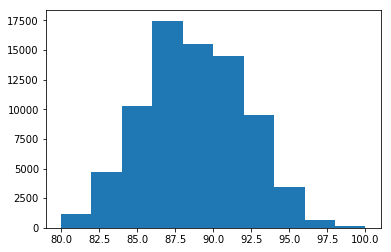

In [22]:

plt.hist(x=vino["points"])
plt.show()

Claro, visualizar información facilita el entendimiento. Aún podemos mejorar un poco el gráfico

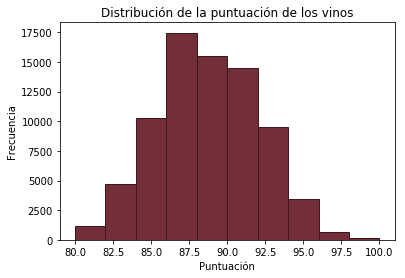

In [23]:
plt.hist(x=vino["points"], color = "#722f37", edgecolor = "#3c191d")
plt.title("Distribución de la puntuación de los vinos")
plt.xlabel("Puntuación")
plt.ylabel("Frecuencia")
plt.show()

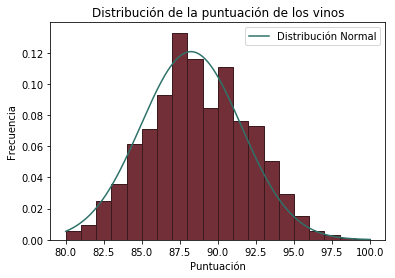

In [24]:
import scipy.stats as stats
lnspc = np.linspace(vino["points"].min(), vino["points"].max(), len(vino["points"]))
mu, sigma = stats.norm.fit(vino["points"])
pdf_normal = stats.norm.pdf(lnspc, mu, sigma) 
plt.plot(lnspc, pdf_normal, label="Distribución Normal", color = "#2f726a") 

plt.hist(x=vino["points"], color = "#722f37", edgecolor = "#3c191d", density = True, bins=20)
plt.title("Distribución de la puntuación de los vinos")
plt.xlabel("Puntuación")
plt.ylabel("Frecuencia")
plt.legend()

plt.show()



In [25]:
pdf_normal = stats.norm.pdf(lnspc, mu, sigma) 

Recordemos que el sitio sólo publica reseñas de vinos que tengan una puntuación mayor a 80.

Observemos ahora la distribución de los precios

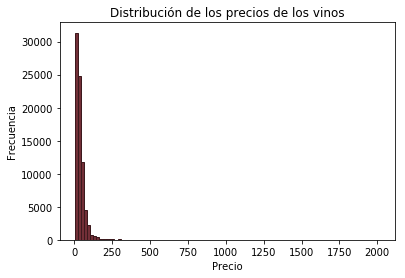

In [26]:
plt.hist(x=vino["price"], color = "#722f37", edgecolor = "#3c191d", bins= 100)
plt.title("Distribución de los precios de los vinos")
plt.xlabel("Precio")
plt.ylabel("Frecuencia")
plt.show()

Parece que hay muy pocos vinos con precio mayor a $300. Intentemos ver un zoom de la distribución:

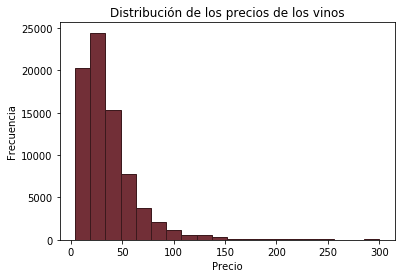

In [27]:
plt.hist(x=vino[vino["price"] <= 300]["price"], color = "#722f37", edgecolor = "#3c191d", bins= 20)
plt.title("Distribución de los precios de los vinos")
plt.xlabel("Precio")
plt.ylabel("Frecuencia")
plt.show()

Observemos las siguientes variables. Veamos cuántas provincias, regiones y viñas hay:

Variable 1: country
Variable 2: description
Variable 3: designation
Variable 4: points
Variable 5: price
Variable 6: province
Variable 7: region_1
Variable 8: region_2
Variable 9: variety
Variable 10: winery

In [28]:
print ( "Número de provincias: " + str(len(vino["province"].unique())))
print ( "Número de regiones: " + str(len(vino["region_1"].unique())))
print ( "Número de bodegas: " + str(len(vino["winery"].unique())))

Número de provincias: 62
Número de regiones: 1086
Número de bodegas: 8652


Finalmente, veamos cuántas variedades de vino hay en el dataset

In [29]:
print ( "Número de variedades de vino: " + str(len(vino["variety"].unique())))

Número de variedades de vino: 427


Listo, hemos concluido con una breve exploración del data set. Podemos pasar a visualizar nuestros datos (aunque ya visualizamos anes las distribuciones, veamos qué más encontramos).

### Visualización en matplotlib


¿Qué podemos visualizar en los datos?

Una opción es ver cuántos vinos hay de cada país

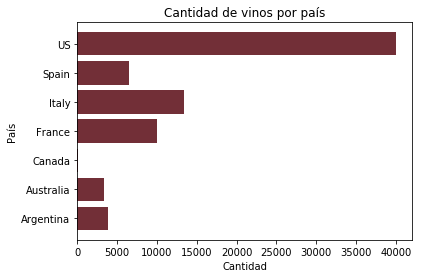

In [30]:
plt.barh(vino["country"].value_counts(sort = True).index, vino["country"].value_counts(sort = True), color = "#722f37")
plt.title("Cantidad de vinos por país")
plt.xlabel("Cantidad")
plt.ylabel("País")
plt.show()

Dentro de cada país también podemos ver cómo se reparte la producción por región 

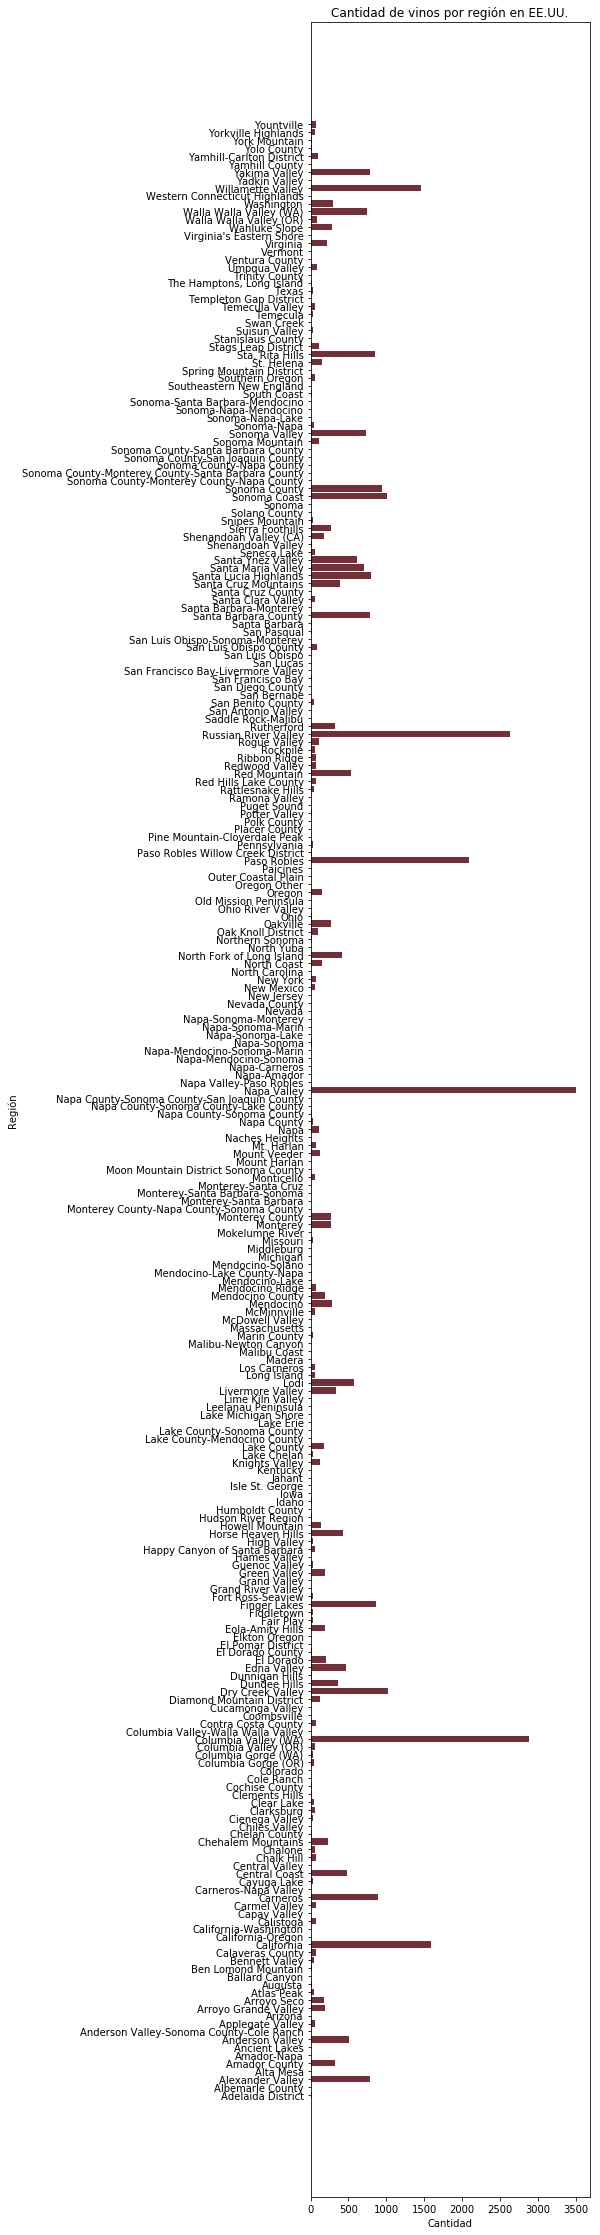

In [31]:
vino_US = vino[vino["country"] == "US"]

plt.figure(figsize=(5,40))
plt.barh(vino_US["region_1"].value_counts().index, vino_US["region_1"].value_counts(), color = "#722f37")
plt.title("Cantidad de vinos por región en EE.UU.")
plt.xlabel("Cantidad")
plt.ylabel("Región")
plt.show()

Esto puede hacerse para cada país.

También puede hacerse por provincia

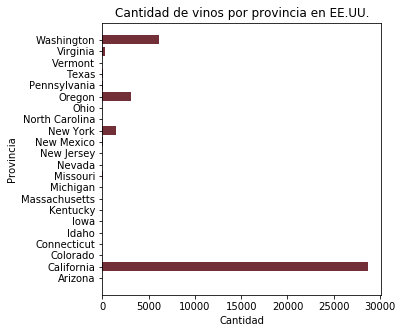

In [32]:
vino_US = vino[vino["country"] == "US"]

plt.figure(figsize=(5,5))
plt.barh(vino_US["province"].value_counts().index, vino_US["province"].value_counts(), color = "#722f37")
plt.title("Cantidad de vinos por provincia en EE.UU.")
plt.xlabel("Cantidad")
plt.ylabel("Provincia")
plt.show()

Podemos visualizar también cosas que no estén de manera explícita en el dataset. Por ejemplo, ¿Qué país tiene el vino, en promedio, más barato?

In [33]:
vino.groupby("country").mean()["price"]

country
Argentina    23.820723
Australia    36.857575
Canada       39.958042
France       45.536068
Italy        40.149158
Spain        29.281555
US           37.471356
Name: price, dtype: float64

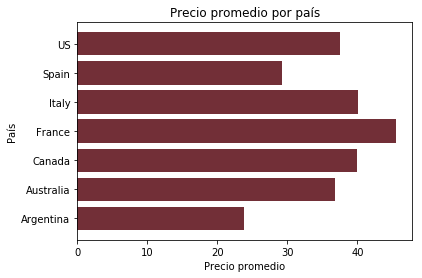

In [34]:
plt.barh(vino.groupby("country").mean()["price"].index, vino.groupby("country").mean()["price"], color = "#722f37")
plt.title("Precio promedio por país")
plt.xlabel("Precio promedio")
plt.ylabel("País")


plt.show()

Argentina tiene el precio promedio más barato.

¿Quién tiene el vino promedio de mayor calidad?

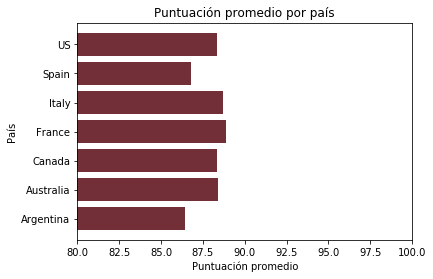

In [35]:
plt.barh(vino.groupby("country").mean()["points"].index, vino.groupby("country").mean()["points"], color = "#722f37")
plt.title("Puntuación promedio por país")
plt.xlabel("Puntuación promedio")
plt.ylabel("País")
plt.xlim(vino["points"].min(),vino["points"].max())

plt.show()

Es dificil notar cuál es la puntuación de cada uno, podemos mejorar este aspecto

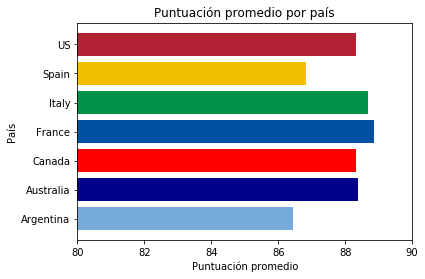

In [36]:
colores = ("#75AADB",
           "#00008B",
           "#ff0000",
           "#0050A4",
           "#009246",
           "#F1BF00",
           "#B22234"    
            )


plt.barh(vino.groupby("country").mean()["points"].index, vino.groupby("country").mean()["points"], color = colores)
plt.title("Puntuación promedio por país")
plt.xlabel("Puntuación promedio")
plt.ylabel("País")
plt.xlim(80,90)

plt.show()

Esto se ve mejor y se puede notar más facilmente qué país tiene la mayor puntuación promedio.

Ahora veamos otro tipo de gráficos que podemos hacer

Primero debemos crear una lista con los puntos para cada país. Primero creemos una lista con los nombres de los países:

In [37]:
paises = list(vino["country"].unique())

Luego, procedemos a la lista de valores para cada país:

In [38]:
#data_boxplot.append(vino[vino["country"] == list(vino["country"].unique())[0]]["points"])

data_boxplot=[]
for pais in paises:
    
    data_boxplot.append(vino[vino["country"] == pais]["points"])

In [39]:
for pais in paises:
    print(pais)

US
Spain
France
Italy
Argentina
Canada
Australia


Ahora podemos hacer nuestro gráfico:

C:\Users\jonas\Anaconda3\lib\site-packages\numpy\core\fromnumeric.py:57: FutureWarning: reshape is deprecated and will raise in a subsequent release. Please use .values.reshape(...) instead
  return getattr(obj, method)(*args, **kwds)


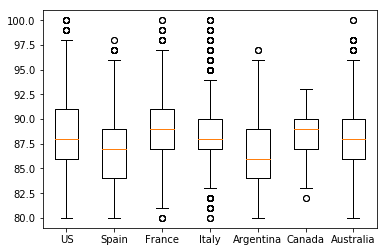

In [40]:

plt.boxplot(data_boxplot)
plt.xticks(np.arange(7)+1 ,paises)
plt.show()

Listo, este gráfico da más información sobre la distribución de los puntos, pero podemos presentarlo mejor:

C:\Users\jonas\Anaconda3\lib\site-packages\numpy\core\fromnumeric.py:57: FutureWarning: reshape is deprecated and will raise in a subsequent release. Please use .values.reshape(...) instead
  return getattr(obj, method)(*args, **kwds)


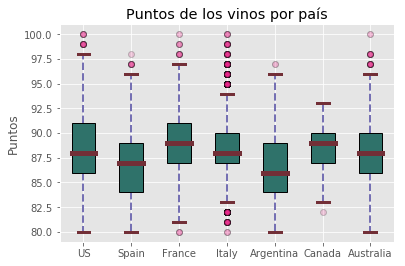

In [41]:
#2f726a
#722f37

with plt.style.context(['ggplot']):
    

        bp = plt.boxplot(data_boxplot,patch_artist=True)
        plt.xticks(np.arange(7)+1 ,paises)

        for box in bp["boxes"]:
            box.set(facecolor = "#2f726a")

        for median in bp["medians"]:
            median.set(color = "#722f37", linewidth=5)

        for whisker in bp['whiskers']:
            whisker.set(color='#7570b3', linewidth=2, linestyle= "--")

        for cap in bp['caps']:
            cap.set(color='#722f37', linewidth=3)

        for flier in bp['fliers']:
            flier.set_marker("o")
            flier.set_markerfacecolor('#e7298a')
            flier.set_alpha(0.1)

        plt.title("Puntos de los vinos por país")
        plt.ylabel("Puntos")
        plt.show()

Podemos hacer lo mismo para los precios:

In [42]:
precios_boxplot=[]
for pais in paises:
    
    precios_boxplot.append(vino[vino["country"] == pais]["price"])

C:\Users\jonas\Anaconda3\lib\site-packages\numpy\core\fromnumeric.py:57: FutureWarning: reshape is deprecated and will raise in a subsequent release. Please use .values.reshape(...) instead
  return getattr(obj, method)(*args, **kwds)


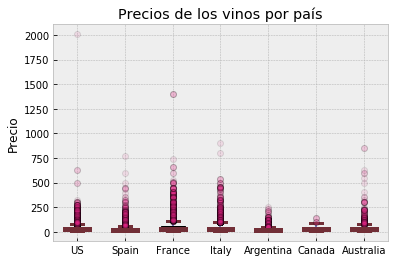

In [43]:
#2f726a
#722f37

with plt.style.context(['bmh']):
    

        bp = plt.boxplot(precios_boxplot,patch_artist=True)
        plt.xticks(np.arange(7)+1 ,paises)

        for box in bp["boxes"]:
            box.set(facecolor = "#2f726a")

        for median in bp["medians"]:
            median.set(color = "#722f37", linewidth=5)

        for whisker in bp['whiskers']:
            whisker.set(color='#7570b3', linewidth=2, linestyle= "--")

        for cap in bp['caps']:
            cap.set(color='#722f37', linewidth=3)

        for flier in bp['fliers']:
            flier.set_marker("o")
            flier.set_markerfacecolor('#e7298a')
            flier.set_alpha(0.1)

        plt.title("Precios de los vinos por país")
        plt.ylabel("Precio")
        
        plt.show()

Parece que hay demasiados outliers, intentemos entonces ver qué ocurre con la dsitribución de los vinos baratos. COnsideremos que barato es menor a $250.

In [44]:
baratos_boxplot=[]
for pais in paises:
    
    baratos_boxplot.append(vino[vino["country"] == pais][vino["price"] <= 200]["price"])

C:\Users\jonas\Anaconda3\lib\site-packages\ipykernel_launcher.py:4: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  after removing the cwd from sys.path.


C:\Users\jonas\Anaconda3\lib\site-packages\numpy\core\fromnumeric.py:57: FutureWarning: reshape is deprecated and will raise in a subsequent release. Please use .values.reshape(...) instead
  return getattr(obj, method)(*args, **kwds)


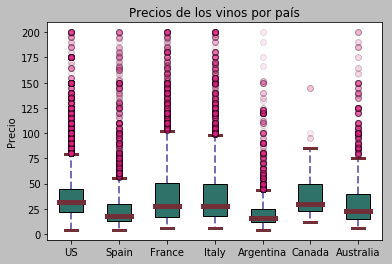

In [45]:
#2f726a
#722f37

with plt.style.context(['grayscale']):
    

        bp = plt.boxplot(baratos_boxplot,patch_artist=True)
        plt.xticks(np.arange(7)+1 ,paises)

        for box in bp["boxes"]:
            box.set(facecolor = "#2f726a")

        for median in bp["medians"]:
            median.set(color = "#722f37", linewidth=5)

        for whisker in bp['whiskers']:
            whisker.set(color='#7570b3', linewidth=2, linestyle= "--")

        for cap in bp['caps']:
            cap.set(color='#722f37', linewidth=3)

        for flier in bp['fliers']:
            flier.set_marker("o")
            flier.set_markerfacecolor('#e7298a')
            flier.set_alpha(0.1)

        plt.title("Precios de los vinos por país")
        plt.ylabel("Precio")
        
        plt.show()

Muy bien, hagamos una última cosa. Puede ser interesante ver la relación entre precios y puntos, revisemos de nuevo nuestro datadet:

In [46]:
vino.head()

,country,description,designation,points,price,province,region_1,variety,winery
0,US,This tremendous 100% varietal wine hails from ...,Martha's Vineyard,96,235.0,California,Napa Valley,Cabernet Sauvignon,Heitz
1,Spain,"Ripe aromas of fig, blackberry and cassis are ...",Carodorum Selección Especial Reserva,96,110.0,Northern Spain,Toro,Tinta de Toro,Bodega Carmen Rodríguez
2,US,Mac Watson honors the memory of a wine once ma...,Special Selected Late Harvest,96,90.0,California,Knights Valley,Sauvignon Blanc,Macauley
3,US,"This spent 20 months in 30% new French oak, an...",Reserve,96,65.0,Oregon,Willamette Valley,Pinot Noir,Ponzi
4,France,"This is the top wine from La Bégude, named aft...",La Brûlade,95,66.0,Provence,Bandol,Provence red blend,Domaine de la Bégude


Podemos hacer una columna nueva para ver el precio de cada punto para cada vino:

In [47]:
vino["points per price"] = vino["points"] / vino["price"]

In [48]:
vino

,country,description,designation,points,price,province,region_1,variety,winery,points per price
0,US,This tremendous 100% varietal wine hails from ...,Martha's Vineyard,96,235.0,California,Napa Valley,Cabernet Sauvignon,Heitz,0.408511
1,Spain,"Ripe aromas of fig, blackberry and cassis are ...",Carodorum Selección Especial Reserva,96,110.0,Northern Spain,Toro,Tinta de Toro,Bodega Carmen Rodríguez,0.872727
2,US,Mac Watson honors the memory of a wine once ma...,Special Selected Late Harvest,96,90.0,California,Knights Valley,Sauvignon Blanc,Macauley,1.066667
3,US,"This spent 20 months in 30% new French oak, an...",Reserve,96,65.0,Oregon,Willamette Valley,Pinot Noir,Ponzi,1.476923
4,France,"This is the top wine from La Bégude, named aft...",La Brûlade,95,66.0,Provence,Bandol,Provence red blend,Domaine de la Bégude,1.439394
5,Spain,"Deep, dense and pure from the opening bell, th...",Numanthia,95,73.0,Northern Spain,Toro,Tinta de Toro,Numanthia,1.301370
6,Spain,Slightly gritty black-fruit aromas include a s...,San Román,95,65.0,Northern Spain,Toro,Tinta de Toro,Maurodos,1.461538
7,Spain,Lush cedary black-fruit aromas are luxe and of...,Carodorum Único Crianza,95,110.0,Northern Spain,Toro,Tinta de Toro,Bodega Carmen Rodríguez,0.863636
8,US,This re-named vineyard was formerly bottled as...,Silice,95,65.0,Oregon,Chehalem Mountains,Pinot Noir,Bergström,1.461538
9,US,The producer sources from two blocks of the vi...,Gap's Crown Vineyard,95,60.0,California,Sonoma Coast,Pinot Noir,Blue Farm,1.583333


Veamos qué país tiene, en promedio, la mejor relación calidad-precio:

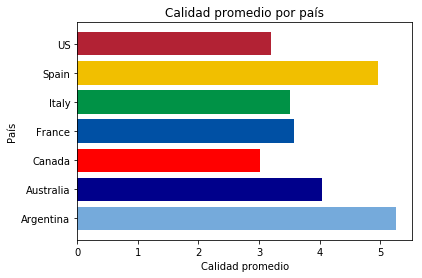

In [49]:
colores = ("#75AADB",
           "#00008B",
           "#ff0000",
           "#0050A4",
           "#009246",
           "#F1BF00",
           "#B22234"    
            )


plt.barh(vino.groupby("country").mean()["points per price"].index, vino.groupby("country").mean()["points per price"], color = colores)
plt.title("Calidad promedio por país")
plt.xlabel("Calidad promedio")
plt.ylabel("País")
#plt.xlim(80,90)

plt.show()

¿Quién tiene el vino con mejor relación calidad costo?

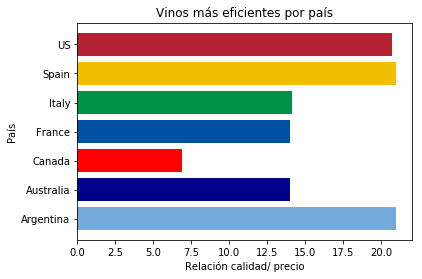

In [50]:
colores = ("#75AADB",
           "#00008B",
           "#ff0000",
           "#0050A4",
           "#009246",
           "#F1BF00",
           "#B22234"    
            )


plt.barh(vino.groupby("country").max()["points per price"].index, vino.groupby("country").max()["points per price"], color = colores)
plt.title("Vinos más eficientes por país")
plt.xlabel("Relación calidad/ precio")
plt.ylabel("País")
#plt.xlim(80,90)

plt.show()

¿Y el peor?

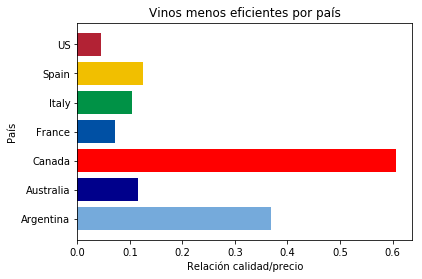

In [51]:
colores = ("#75AADB",
           "#00008B",
           "#ff0000",
           "#0050A4",
           "#009246",
           "#F1BF00",
           "#B22234"    
            )


plt.barh(vino.groupby("country").min()["points per price"].index, vino.groupby("country").min()["points per price"], color = colores)
plt.title("Vinos menos eficientes por país")
plt.xlabel("Relación calidad/precio")
plt.ylabel("País")
#plt.xlim(80,90)

plt.show()

Hasta ahora hemos visualizado variables individuales, pero también podemos visualizar relaciones entre ellas. Por ejemplo, **points** y **price**:

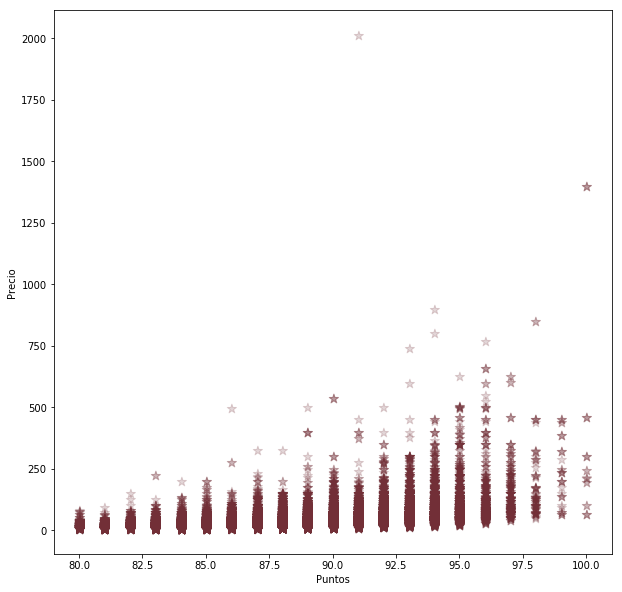

In [73]:
plt.figure(figsize=(10,10))
plt.scatter(x = vino["points"], y = vino["price"], color = "#722f37", alpha = 0.2, marker = r"$\bigstar$", s = 100)

plt.ylabel("Precio")
plt.xlabel("Puntos")
plt.show()

Oh, un pequeño bonus. ¿Recuerdan que tenemos descripciones de los vinos? Pues podemos también visualizar algo al respecto. Si queremos saber cuáles son las palabras más utilizadas:

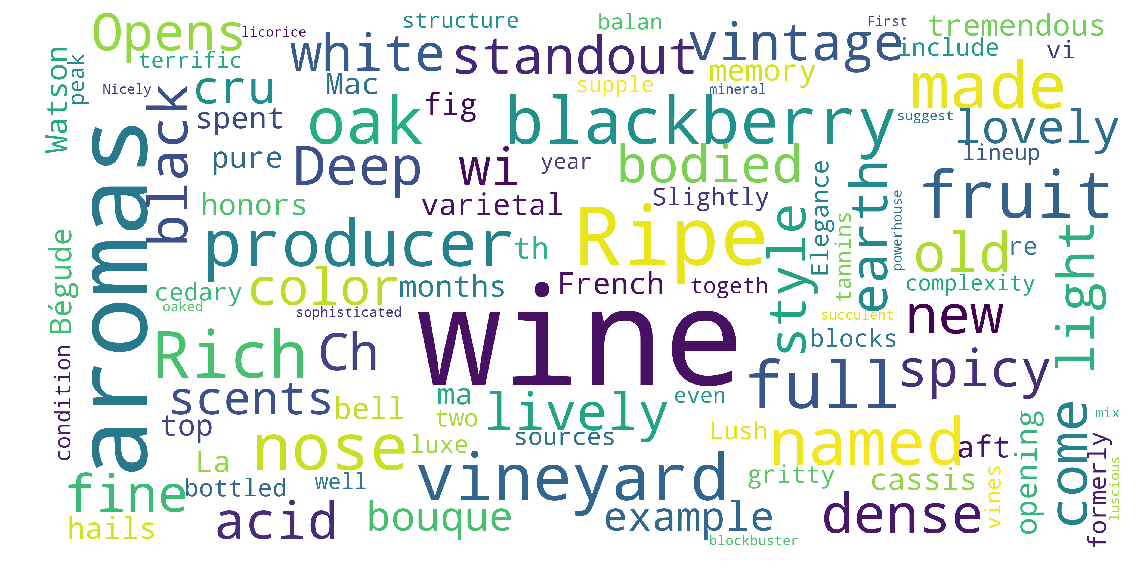

In [87]:
from wordcloud import WordCloud, STOPWORDS

stopwords = set(STOPWORDS)
data = vino


wordcloud = WordCloud(
                          scale = 10,
                          background_color='white',
                          stopwords=stopwords,
                          max_words=100,
                          max_font_size=50, 
                          random_state=False
                         ).generate(str(vino['description']))


#print(wordcloud)
plt.figure(figsize=(20,10))
plt.imshow(wordcloud)
plt.axis('off')
plt.show()
#show wordcloud

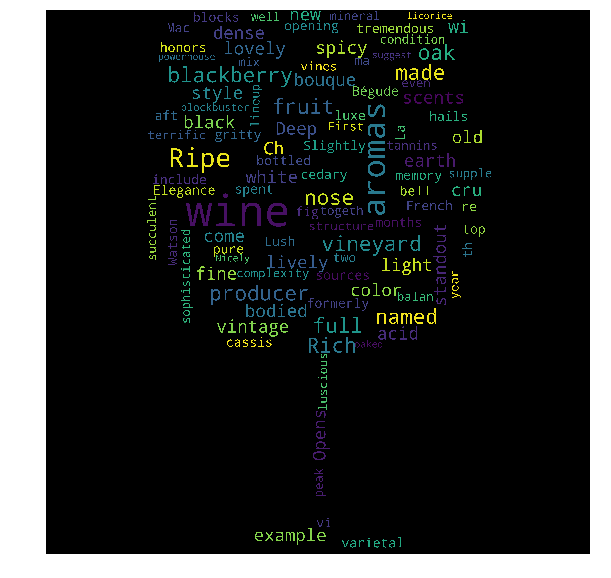

In [99]:
from os import path
from PIL import Image

d = path.dirname("__file__")

wine_mask = np.array(Image.open(path.join(d, "wine-mask.jpg")))

stopwords = set(STOPWORDS)
data = vino


wordcloud = WordCloud(
                          mask= wine_mask,
                          scale = 40,
                          background_color='black',
                          stopwords=stopwords,
                          max_words=100,
                          max_font_size=50, 
                          random_state=False
                         ).generate(str(vino['description']))


#print(wordcloud)
plt.figure(figsize=(20,10))
plt.imshow(wordcloud)
plt.axis('off')
plt.show()
#show wordcloud